# How does the "statistically informative region" around a pixel scale with dataset size?

For a clean pixel $x$ and a noisy pixel $a$ (corrupted by forward diffusion
at inversion time $t$), define the region

$$R(|D|, t) = \{\, a : |\mathrm{Corr}(x_{0,x}, x_{t,a})| > z / \sqrt{|D|} \,\}$$

where $|D|$ is the number of samples used to *estimate* the correlation,
and $z$ is a Bonferroni-corrected z-score (not a bare $z=1$) chosen so that
testing all $H \times W$ pixels simultaneously has a fixed family-wise
false-positive rate. A bare $z=1$ threshold -- the naive "one standard
error" cut -- gives ~32% of genuinely uncorrelated pixels crossing it by
chance alone when tested against ~$10^3$ pixels at once; combined with the
real, weak, long-range correlations present in natural images, that density
exceeds the ~0.59 site-percolation threshold for 4-connectivity on a finite
grid, so scattered false positives spuriously merge into one cluster
spanning most of the image -- contaminating any area/shape measurement
regardless of post-processing. The Bonferroni correction below keeps the
false-positive density low and safely sub-percolation at every $|D|$ and
image size, and `connected_region_containing_target` (see the example cell
below) additionally keeps only the single component spatially touching the
target. As $|D|$ grows, weaker (more distant) correlations become
detectable, so the region should still *grow* -- just without the
percolation artifact dominating that growth.

**Motivating hypothesis (deviation from scale invariance).** Natural images
have an approximately power-law spatial power spectrum, giving a real-space
two-point correlation function $\langle\phi(x)\phi(0)\rangle \sim |x|^{-\epsilon}$
with $\epsilon$ small (close to the marginal/critical case). Setting this
signal equal to the $|D|$-dependent detectability threshold and solving for
the boundary radius gives a **plain power law in $|D|$** (not a logarithm):

$$R \sim |D|^{1/(2\epsilon)} \qquad\Longrightarrow\qquad \mathrm{area} \sim |D|^{1/\epsilon}$$

This means $\epsilon$ can be measured two independent ways: (1) *directly*,
by radially averaging the clean-image correlation map and fitting its
power-law tail, and (2) *indirectly*, from the power-law exponent of how
the region's area grows with $|D|$ ($\epsilon = 1/a$). Agreement between
the two is the real test of this picture -- across three datasets with very
different structure: MNIST (structured strokes, mostly background),
CIFAR-10 (generic natural-image textures), and CelebA (aligned faces,
strong non-stationary structure).

We intentionally draw *exactly* $|D|$ samples to estimate each correlation
(not a large noise-free reference map with only the threshold varying), so
the region's size and shape include real finite-sample fluctuation --
consistent with "what would a dataset of this size actually reveal," not
just the smooth underlying population statistics.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

os.chdir("../")
ROOT = Path(os.path.abspath("")).resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

torch.manual_seed(0)
np.random.seed(0)

In [2]:
from src.utils.data import get_dataset
from src.utils.noise_schedules import cosine_noise_schedule
from src.utils.correlation_region import (
    nested_correlation_curve, correlation_region, sample_x0_xt,
    pixel_correlation_map, radial_correlation_profile, fit_radial_power_law,
)

## Setup

All three datasets are already resized to 32x32 by the shared `get_dataset`
pipeline, so pixel distances are directly comparable across datasets. The
target pixel `x` is the image center for all three (a face-interior
location for CelebA, given its alignment; a location usually inside the
digit's bounding box for MNIST; a generic location for CIFAR-10).

In [3]:
dataset_names = ["mnist", "cifar10", "celeba"]
datasets = {}
for name in dataset_names:
    ds, meta = get_dataset(name, root=str(ROOT / "data"))
    datasets[name] = ds
    print(f"{name}: {len(ds)} images, {meta['image_size']}x{meta['image_size']}, {meta['num_channels']} channel(s)")

IMSIZE = 32
TARGET = (IMSIZE // 2, IMSIZE // 2)
n_values = [100, 300, 1000, 3000, 10000, 30000]
t_values = [0.1, 0.3, 0.5, 0.7, 0.9]

mnist: 60000 images, 32x32, 1 channel(s)


Files already downloaded and verified


cifar10: 50000 images, 32x32, 3 channel(s)
Files already downloaded and verified


celeba: 162770 images, 32x32, 3 channel(s)


## Example correlation maps and thresholded regions

One illustrative example per dataset: the raw correlation map
$\mathrm{Corr}(x_{0,\mathrm{target}}, x_{t,a})$ for every pixel $a$, the raw
thresholded mask $|{\rm corr}| > 1/\sqrt{|D|}$, and the connected component
of that mask touching the target pixel.

**Why the connected component, and not the raw mask, is the region we
report.** Even with the Bonferroni-corrected threshold, a handful of
pixels can still cross it by chance scattered around the frame. That
speckle is visible directly below: the raw mask (middle row) can show a few
scattered dots outside the main blob, while the true informative
neighborhood around the target is the contiguous component that survives
in the connected region (bottom row). All region-size and shape statistics
used in the rest of this notebook are computed on the connected component,
not the raw mask.

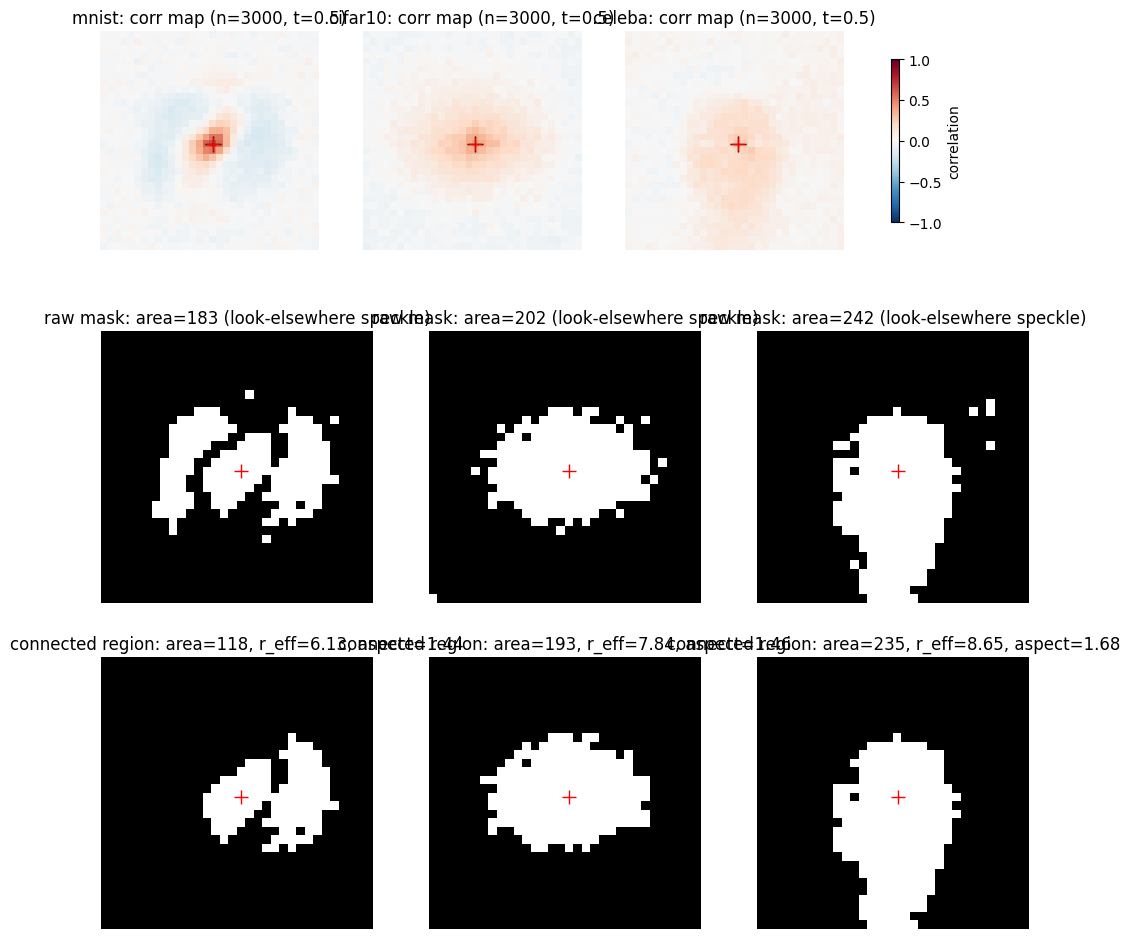

In [4]:
fig, axes = plt.subplots(3, len(dataset_names), figsize=(4 * len(dataset_names), 12))
example_n, example_t = 3000, 0.5
for col, name in enumerate(dataset_names):
    out = correlation_region(datasets[name], n_samples=example_n, t=example_t,
                              schedule=cosine_noise_schedule, target=TARGET, seed=0)
    im0 = axes[0, col].imshow(out["corr_map"], cmap="RdBu_r", vmin=-1, vmax=1)
    axes[0, col].set_title(f"{name}: corr map (n={example_n}, t={example_t})")
    axes[0, col].plot(TARGET[1], TARGET[0], "k+", markersize=12)
    axes[1, col].imshow(out["raw_mask"], cmap="gray")
    axes[1, col].set_title(f"raw mask: area={int(out['raw_mask'].sum())} "
                            f"(look-elsewhere speckle)")
    axes[2, col].imshow(out["mask"], cmap="gray")
    axes[2, col].set_title(f"connected region: area={out['area']}, r_eff={out['r_eff']:.2f}, "
                            f"aspect={out['aspect_ratio']:.2f}")
    for ax in (axes[0, col], axes[1, col], axes[2, col]):
        ax.axis("off")
        ax.plot(TARGET[1], TARGET[0], "r+", markersize=10)
fig.colorbar(im0, ax=axes[0, :].tolist(), shrink=0.6, label="correlation")
plt.show()

## Main sweep: region size and shape vs. dataset size and noise

In [5]:
results = {}  # (dataset, t) -> {n: stats}
for name in dataset_names:
    for t in t_values:
        results[(name, t)] = nested_correlation_curve(
            datasets[name], n_values=n_values, t=t, schedule=cosine_noise_schedule,
            target=TARGET, seed=42,
        )
    print(f"{name}: done")

mnist: done


cifar10: done


celeba: done


## Direct measurement of the natural-image correlation decay exponent $\epsilon$

Independent of any diffusion corruption or dataset-size detectability
threshold: radially average the **clean** ($t=0$) pixel-pixel correlation
map around the target pixel, then fit its power-law tail
$|C(r)| \sim r^{-\epsilon}$. This $\epsilon$ is a property of the raw image
statistics alone (motivated by natural images having an approximately
power-law spatial power spectrum, $\langle\phi(x)\phi(0)\rangle \sim |x|^{-\epsilon}$)
-- it should match, independently, the $\epsilon$ extracted below from how
the informative region's *area* grows with $|D|$
($\mathrm{area} \sim |D|^{1/\epsilon}$, from setting the signal
$r^{-\epsilon}$ equal to the $|D|$-dependent detectability threshold).

mnist   : direct epsilon = 1.227 (R2=0.813, n_clean=30000)


cifar10 : direct epsilon = 1.927 (R2=0.813, n_clean=30000)


celeba  : direct epsilon = 1.379 (R2=0.877, n_clean=30000)


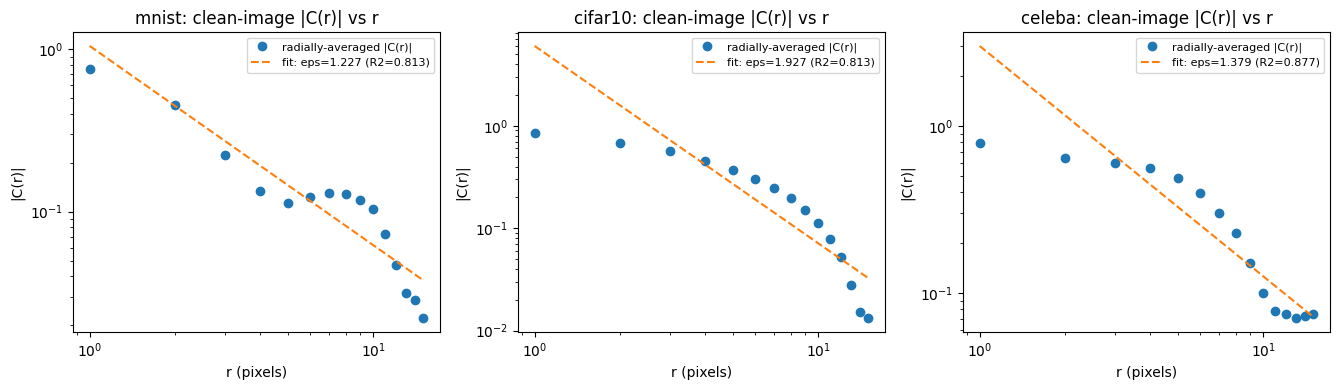

In [6]:
N_CLEAN = 30000  # largest sample size used elsewhere, for a low-noise clean-correlation estimate
direct_epsilon = {}  # dataset -> (epsilon, r2)
fig, axes = plt.subplots(1, len(dataset_names), figsize=(4.5 * len(dataset_names), 4))
for col, name in enumerate(dataset_names):
    n_clean = min(N_CLEAN, len(datasets[name]))
    x0_clean, xt_clean = sample_x0_xt(datasets[name], n_samples=n_clean, t=0.0,
                                       schedule=cosine_noise_schedule, seed=123)
    clean_corr_map = pixel_correlation_map(x0_clean, xt_clean, TARGET)
    radii, values = radial_correlation_profile(clean_corr_map, TARGET)
    epsilon, r2 = fit_radial_power_law(radii, values, r_min=2)
    direct_epsilon[name] = (epsilon, r2)

    valid = (radii >= 2) & (values > 0)
    fit_vals = np.exp(np.polyval(np.polyfit(np.log(radii[valid]), np.log(values[valid]), 1), np.log(radii)))
    axes[col].loglog(radii, values, "o", label="radially-averaged |C(r)|")
    axes[col].loglog(radii, fit_vals, "--", label=f"fit: eps={epsilon:.3f} (R2={r2:.3f})")
    axes[col].set_title(f"{name}: clean-image |C(r)| vs r")
    axes[col].set_xlabel("r (pixels)"); axes[col].set_ylabel("|C(r)|")
    axes[col].legend(fontsize=8)
    print(f"{name:8s}: direct epsilon = {epsilon:.3f} (R2={r2:.3f}, n_clean={n_clean})")
plt.tight_layout()
plt.show()

## Area vs. |D|: plain power law or logarithmic?

This is the primary quantity: does the *area* of the informative region
follow a power law in the training-set size, $\mathrm{area} \sim |D|^a$, as
originally hypothesized? Two versions of the same data: $\ln(\mathrm{area})$
vs. $\ln|D|$ (a straight line here means a plain power law), and
$\ln(\mathrm{area})$ vs. $\ln\ln|D|$ (a straight line here means
$\mathrm{area} \sim (\ln|D|)^{1/\epsilon}$, the scale-invariance-deviation
hypothesis applied directly to area rather than to a derived radius).

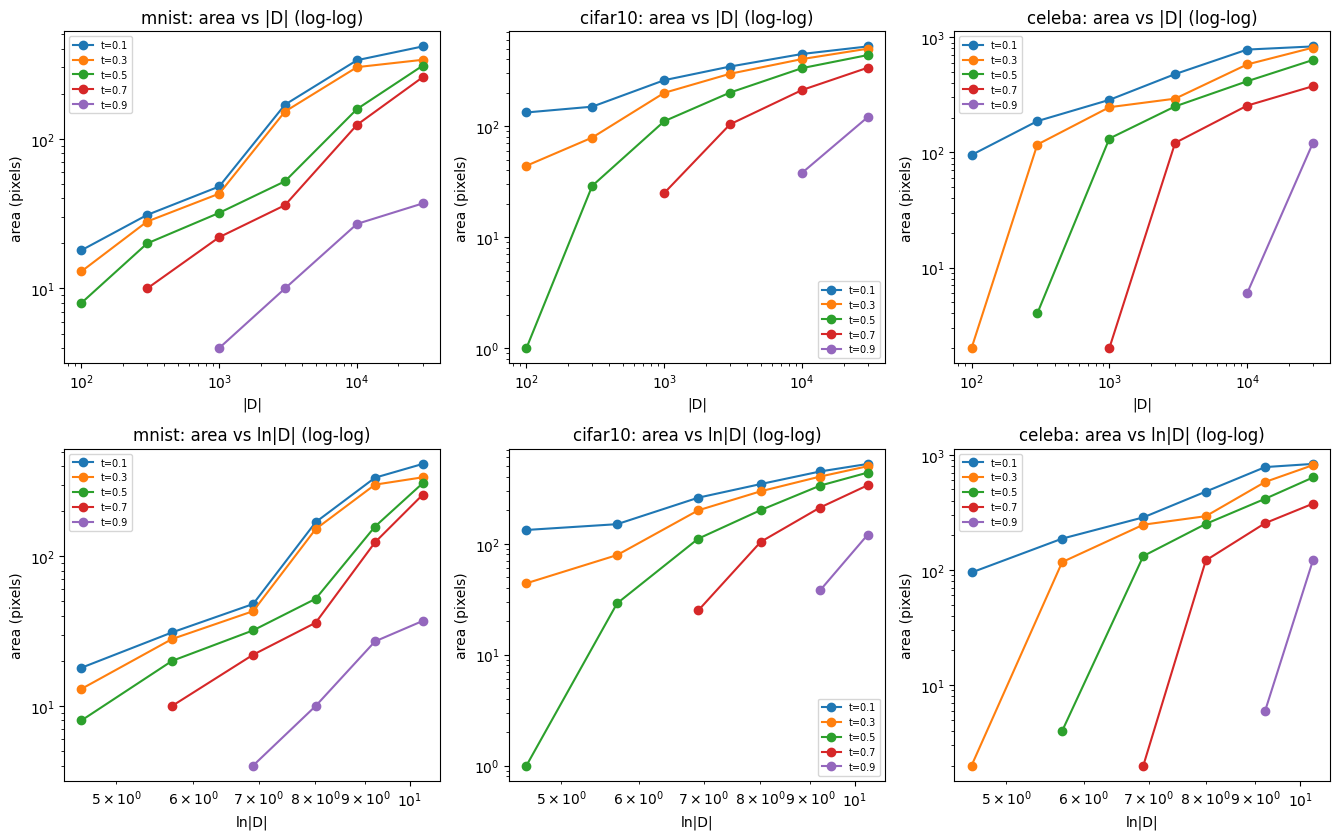

In [7]:
fig, axes = plt.subplots(2, len(dataset_names), figsize=(4.5 * len(dataset_names), 8.5))
for col, name in enumerate(dataset_names):
    for t in t_values:
        curve = results[(name, t)]
        ns = np.array(sorted(curve))
        area = np.array([curve[n]["area"] for n in ns], dtype=float)
        valid = area > 0
        axes[0, col].plot(ns[valid], area[valid], marker="o", label=f"t={t}")
        axes[1, col].plot(np.log(ns[valid]), area[valid], marker="o", label=f"t={t}")
    axes[0, col].set_xscale("log"); axes[0, col].set_yscale("log")
    axes[0, col].set_title(f"{name}: area vs |D| (log-log)")
    axes[0, col].set_xlabel("|D|"); axes[0, col].set_ylabel("area (pixels)")
    axes[1, col].set_xscale("log"); axes[1, col].set_yscale("log")
    axes[1, col].set_title(f"{name}: area vs ln|D| (log-log)")
    axes[1, col].set_xlabel("ln|D|"); axes[1, col].set_ylabel("area (pixels)")
    axes[0, col].legend(fontsize=7); axes[1, col].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Fitted exponents, and comparison against the direct measurement

For each (dataset, t), fit a straight line to both log-log representations
of **area** (the primary quantity) and compare the goodness of fit ($R^2$)
-- whichever representation straightens the curve out better is the more
likely true scaling regime. $R_\mathrm{eff}$ (an effective radius,
$\sqrt{\mathrm{area}/\pi}$) is included alongside purely as a derived,
complementary view -- since $\mathrm{area} \propto R_\mathrm{eff}^2$ for a
compact blob, its fitted exponent is expected to run at about half of
area's, with the same $R^2$.

Per the motivating hypothesis, the physically correct epsilon comes from
the **plain power-law** fit of area vs. $|D|$: $\mathrm{area} \sim |D|^a$
gives $\epsilon_\mathrm{region} = 1/a$. This is compared directly against
$\epsilon_\mathrm{direct}$, measured above from the clean-image radial
correlation decay -- agreement between the two (independent) measurements
is the real test of the scaling picture, not either fit's $R^2$ alone.

In [8]:
def loglog_fit(x, y):
    # least-squares fit of ln(y) = a*ln(x) + b; returns (slope, r_squared)
    valid = (x > 0) & (y > 0)
    lx, ly = np.log(x[valid]), np.log(y[valid])
    if valid.sum() < 3:
        return np.nan, np.nan
    a, b = np.polyfit(lx, ly, 1)
    pred = a * lx + b
    ss_res = np.sum((ly - pred) ** 2)
    ss_tot = np.sum((ly - ly.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return a, r2


rows = []
for name in dataset_names:
    eps_direct, r2_direct = direct_epsilon[name]
    for t in t_values:
        curve = results[(name, t)]
        ns = np.array(sorted(curve))
        area = np.array([curve[n]["area"] for n in ns], dtype=float)
        r_eff = np.array([curve[n]["r_eff"] for n in ns])

        a_area, r2_area_plain = loglog_fit(ns.astype(float), area)
        b_area, r2_area_log = loglog_fit(np.log(ns.astype(float)), area)
        eps_region = 1.0 / a_area if a_area not in (0, np.nan) else np.nan

        alpha, r2_plain = loglog_fit(ns.astype(float), r_eff)
        b, r2_log = loglog_fit(np.log(ns.astype(float)), r_eff)

        rows.append((name, t, a_area, r2_area_plain, b_area, r2_area_log, eps_region,
                     eps_direct, alpha, r2_plain, b, r2_log))
        print(f"{name:8s} t={t:.1f}: "
              f"area~|D|^a  a={a_area:6.3f} (R2={r2_area_plain:.3f}, eps_region=1/a={eps_region:6.3f})  |  "
              f"eps_direct={eps_direct:6.3f} (R2={r2_direct:.3f})  |  "
              f"area~(ln|D|)^b  b={b_area:6.3f} (R2={r2_area_log:.3f})  |  "
              f"[R_eff: a={alpha:6.3f} (R2={r2_plain:.3f})]")

mnist    t=0.1: area~|D|^a  a= 0.600 (R2=0.966, eps_region=1/a= 1.667)  |  eps_direct= 1.227 (R2=0.813)  |  area~(ln|D|)^b  b= 4.233 (R2=0.954)  |  [R_eff: a= 0.300 (R2=0.966)]
mnist    t=0.3: area~|D|^a  a= 0.614 (R2=0.963, eps_region=1/a= 1.628)  |  eps_direct= 1.227 (R2=0.813)  |  area~(ln|D|)^b  b= 4.366 (R2=0.964)  |  [R_eff: a= 0.307 (R2=0.963)]
mnist    t=0.5: area~|D|^a  a= 0.621 (R2=0.985, eps_region=1/a= 1.609)  |  eps_direct= 1.227 (R2=0.813)  |  area~(ln|D|)^b  b= 4.361 (R2=0.962)  |  [R_eff: a= 0.311 (R2=0.985)]
mnist    t=0.7: area~|D|^a  a= 0.715 (R2=0.986, eps_region=1/a= 1.398)  |  eps_direct= 1.227 (R2=0.813)  |  area~(ln|D|)^b  b= 5.514 (R2=0.966)  |  [R_eff: a= 0.358 (R2=0.986)]
mnist    t=0.9: area~|D|^a  a= 0.673 (R2=0.964, eps_region=1/a= 1.486)  |  eps_direct= 1.227 (R2=0.813)  |  area~(ln|D|)^b  b= 5.763 (R2=0.980)  |  [R_eff: a= 0.337 (R2=0.964)]
cifar10  t=0.1: area~|D|^a  a= 0.260 (R2=0.970, eps_region=1/a= 3.847)  |  eps_direct= 1.927 (R2=0.813)  |  area~(l

## Region shape vs. dataset size

Does the region's shape (aspect ratio of its best-fit ellipse; 1.0 =
isotropic/circular) settle onto a consistent asymptotic value as $|D|$
grows, and is that asymptotic shape similar across datasets?

Points with `area < MIN_AREA_FOR_ASPECT` are dropped before plotting: a
region of only 1-2 connected pixels has a numerically near-zero minor axis,
which makes its aspect ratio blow up to a numerically meaningless value
(the ellipse fit is only meaningful once the region has enough pixels to
have a well-defined shape at all).

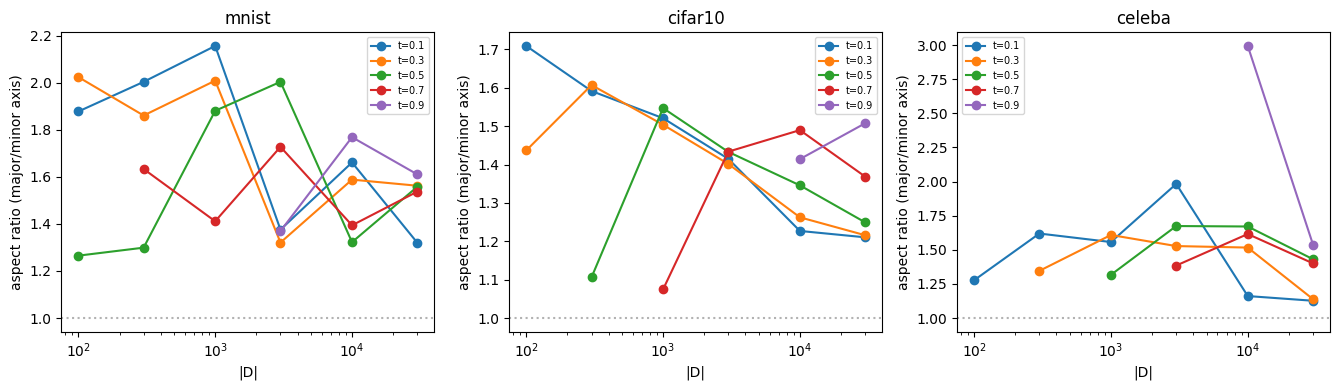

In [9]:
MIN_AREA_FOR_ASPECT = 5

fig, axes = plt.subplots(1, len(dataset_names), figsize=(4.5 * len(dataset_names), 4))
for col, name in enumerate(dataset_names):
    for t in t_values:
        curve = results[(name, t)]
        ns = np.array(sorted(curve))
        aspect = np.array([curve[n]["aspect_ratio"] for n in ns])
        area = np.array([curve[n]["area"] for n in ns])
        valid = area >= MIN_AREA_FOR_ASPECT
        axes[col].plot(ns[valid], aspect[valid], marker="o", label=f"t={t}")
    axes[col].set_xscale("log")
    axes[col].axhline(1.0, color="gray", linestyle=":", alpha=0.6)
    axes[col].set_xlabel("|D|"); axes[col].set_ylabel("aspect ratio (major/minor axis)")
    axes[col].set_title(name)
    axes[col].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Interpretation

- **Agreement between $\epsilon_\mathrm{direct}$ and $\epsilon_\mathrm{region}$**
  (the two columns compared in the fitted-exponents table above) is the
  actual test of the scaling picture: $\epsilon_\mathrm{direct}$ comes from
  the clean image's own real-space correlation decay, entirely independent
  of the diffusion/dataset-size experiment, while $\epsilon_\mathrm{region}$
  is backed out from how the detectable region's area grows with $|D|$. If
  they agree (roughly, and ideally across $t$, since diffusion should only
  rescale the correlation's amplitude, not its spatial decay exponent),
  that supports the picture that region growth is driven by the underlying
  power-law image statistics, not some unrelated effect. Divergence would
  mean something else (e.g. non-stationarity, or a residual detection-bias
  artifact) is contaminating the area-vs-$|D|$ measurement.
- **Consistency across datasets** in $\epsilon_\mathrm{direct}$ would
  support a universal underlying mechanism (natural image statistics being
  close to scale-invariant in general); a large spread would suggest
  dataset-specific structure (e.g. CelebA's strong alignment, MNIST's
  sparse strokes) dominates over any universal image-statistics effect.
- **Shape**: an aspect ratio that stays near 1 across all $|D|$ and
  datasets would mean the informative region is essentially isotropic
  (radially symmetric) regardless of dataset content; systematic
  elongation (especially for CelebA, where the center pixel sits in a
  highly structured, non-stationary region of the aligned face) would show
  up as an aspect ratio well above 1, and possibly growing or shrinking
  with $|D|$ if finite-sample noise dominates the shape at small $|D|$.